# 2026 Microbial species frequencies and community phenotype
# Principal component analyses

In [1]:
cwd = "/scratch/project_2000746/anthosun/2026FQPH/"

In [2]:
import numpy as np
import scipy as sp
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.decomposition import PCA

In [3]:
from sklearn.cluster import KMeans

## Simple functions

In [4]:
def turn_labels_to_str(frame):
    df = frame.copy()
    if isinstance(df.index, pd.MultiIndex):
        index = pd.MultiIndex.from_frame(df.index.to_frame().astype(str), names = df.index.names)
    else:
        index = pd.Index(df.index, dtype=str, name = df.index.name)
        
    if isinstance(df.columns, pd.MultiIndex):
        columns = pd.MultiIndex.from_frame(df.columns.to_frame().astype(str), names = df.columns.names)
    else:
        columns = pd.Index(df.columns, dtype=str, name = df.columns.name)

    df.index = index
    df.columns = columns
    
    return df

In [2]:
# PCA: variance explained plot

def draw_pca_bars(ax, pca, zorder=1, xlabel="principal component", ylabel="variance explained"):
    
    pca_bars = [range(1, len(pca.explained_variance_ratio_) + 1),
                pca.explained_variance_ratio_,
                np.cumsum(pca.explained_variance_ratio_),]

    ys = np.arange(0, 11, 1) / 10
    for y in ys:
        ax.axhline(y, c = "k", alpha = 0.3, zorder = zorder)
    
    ax.bar(pca_bars[0], pca_bars[2], zorder = zorder + 1)
    ax.bar(pca_bars[0], pca_bars[1], zorder = zorder + 1)
    
    ax.set_xticks(np.arange(len(pca.explained_variance_ratio_)) + 1)
    ax.set_yticks(ys)
    ax.set_xlim(0.5, len(pca.explained_variance_ratio_) + 0.5)
    ax.set_ylim(0,1)
    
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

In [1]:
# PCA biplot

def draw_pca_target(ax,
                    pca, # PCA object
                    axes, # PCA-axes to plot, e.g. (0,1)
                    featurelabels, # feature names to annotate
                    featurecolors = "k",
                    scatter = None, # datapoints to scatter
                    rays = [0.05, 0.10], # size of the target-circles
                   ):
    
    x, y = axes
    ratios = pca.explained_variance_ratio_ # to fill in the axis-labels as percentage of explained variance
    loadings = pca.components_ * np.sqrt(pca.explained_variance_)[:,np.newaxis] # arrow sizes
    if isinstance(featurecolors, str): # set up arrow colors
        featurecolors = [featurecolors] * len(featurelabels)
    
    # draw target
    ax.axhline(0, c="k", alpha=0.3, ls="dotted")
    ax.axvline(0, c="k", alpha=0.3, ls="dotted")
    for r, ray in enumerate(rays):
        circle = plt.Circle((0, 0), ray, color="k", alpha=0.3, ls=["dotted", "dashed"][r % 2], fill=False)
        ax.add_patch(circle)
    
    if not scatter is None:
        components = pca.fit_transform(scatter)
        ax.scatter(components[:,x], components[:,y])
    
    for i, feature in enumerate(featurelabels):
        ax.annotate(feature, xy=(0,0), xytext=(loadings[x,i], loadings[y,i]),
                    arrowprops={"arrowstyle":"<|-", "color": featurecolors[i], },)
    
    ax.set_xlim(loadings[x].min(), loadings[x].max())
    ax.set_ylim(loadings[y].min(), loadings[y].max())
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("principal component {} ({} %)".format(x + 1, round(ratios[x] * 100)) )
    ax.set_ylabel("principal component {} ({} %)".format(y + 1, round(ratios[y] * 100)) )

## Loading data

In [7]:
amps = pd.read_csv("{}/data/[AMP]s.csv".format(cwd))
freqs = pd.read_csv("{}/data/Freqs.csv".format(cwd), header=[0,], index_col=[0,1,2,3,])
summary = pd.read_csv("{}/data/Phnt_strs_normalised_summary.csv".format(cwd), header=[0,1], index_col=[0,1,2,3,])
joint = pd.read_csv("{}/data/Join_freq_phnt.csv".format(cwd), header=[0,1], index_col=[0,1,2,3,])

In [8]:
mask = joint.columns.get_level_values("char") == "freq"

L = joint.index.to_frame() # labels
F = joint.iloc[:,mask] # frequencies
P = joint.iloc[:,~mask] # phenotypes
J = joint.copy()

# PCA on frequencies

## Loading abundance data

In [9]:
freqs = pd.read_csv("{}/data/Freqs.csv".format(cwd), header=[0,], index_col=[0,1,2,3,])
#logfreqs = freqs.apply(lambda x: np.log(x + 1))

## PCA on community composition

In [11]:
# PCA on frequencies

X = freqs

short = "freq"
long = "frequencies (7 timepoints)"

features = X.columns
PCA_thresh = 0.95 # PCA-threshold

pca = PCA(n_components = PCA_thresh, svd_solver = "full")
pca.fit(X)
print("Variance explained:", np.cumsum(pca.explained_variance_ratio_)) # explained variance

imps = np.sqrt( np.sum(pca.components_**2 * pca.explained_variance_[:,np.newaxis], axis=0) )
imps = pd.Series(imps, index=features, name="imps")
print(imps.nlargest(n=5))

Variance explained: [0.51536475 0.75801118 0.89153863 0.94417425 0.97154266]
403     0.137010
1972    0.127269
97      0.080636
1977    0.067037
1287    0.056777
Name: imps, dtype: float64


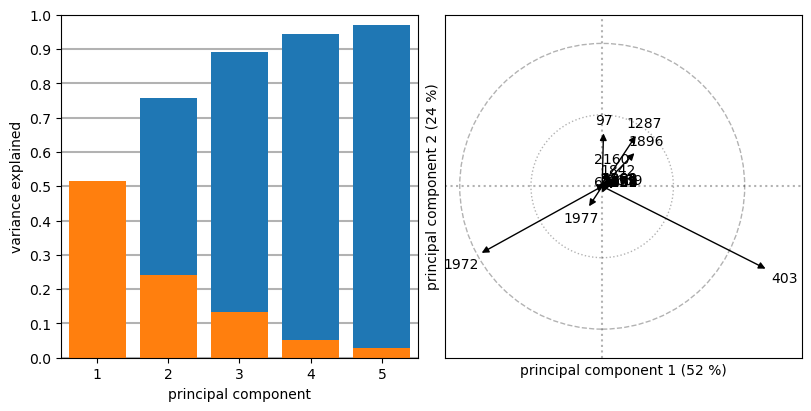

In [15]:
fig = plt.figure(figsize=(8, 4), constrained_layout=True)
#fig.suptitle("PCA on {}".format(long))
gs = fig.add_gridspec(1, 2)

# bar plot
ax = fig.add_subplot(gs[:,0])
draw_pca_bars(ax, pca, zorder=1)

# PCA plot
ax = fig.add_subplot(gs[:,1])
draw_pca_target(ax, pca, axes=(0, 1), featurelabels=features, scatter=None,)
ax.set_xlim(-0.11, 0.14)
ax.set_ylim(-0.12, 0.12)

### SAVING
name = "{}/plot/pcas_{}.pdf".format(cwd, short)
plt.savefig(name, facecolor='w', edgecolor='w', transparent=False, bbox_inches="tight")
plt.show()

# PCA on phenotypes (full curves)

## Loading phenotypic data

In [16]:
N = pd.read_csv("{}/data/Phnt_strs.csv".format(cwd), header=[0,1,2,3,4,], index_col=[0,], )
R = pd.read_csv("{}/data/Phnt_strs_rhos.csv".format(cwd), header=[0,1,2,3,4,], index_col=[0,], )

## PCA-dimensionality of per-cap. growth curves R

In [35]:
# number of principal components capturing 95% variability for each stressor alone

PCA_thresh = 0.95 # PCA-threshold
pca = PCA(n_components = PCA_thresh, svd_solver = "full")
XXX = R.T

features = XXX.columns
pca.fit(XXX)
print("all: {}".format(len(pca.explained_variance_ratio_), ))

for strs in R.columns.get_level_values("strs").unique():
    
    X = XXX.xs(strs, level="strs")
    features = X.columns
    pca.fit(X)
    print("{}: {}".format(strs, len(pca.explained_variance_ratio_), ), #np.cumsum(pca.explained_variance_ratio_),
         ) # explained variance

all: 16
0: 5
AMP: 7
CuSO4: 28
H2O2: 15
IMI: 10
LEV: 35
NaCl: 14
RIF: 35
STR: 18
VAN: 16


In [46]:
# number of principal components capturing 95% variability for each stressor alone

common_days = F.index.get_level_values("days").unique().to_numpy(dtype=float)
real_days = R.columns.get_level_values("days").unique().to_numpy(dtype=float)
real_days_in_common = [str(int(day)) for day in real_days[np.argmin(np.abs(real_days[:,None] - common_days), axis=0)]]

mask = [day in real_days_in_common for day in R.columns.get_level_values("days")]

PCA_thresh = 0.95 # PCA-threshold
pca = PCA(n_components = PCA_thresh, svd_solver = "full")
XXX = R.T.iloc[mask,:]

features = XXX.columns
pca.fit(XXX)
print("all: {}".format(len(pca.explained_variance_ratio_), ))

for strs in R.columns.get_level_values("strs").unique():
    
    X = XXX.xs(strs, level="strs")
    features = X.columns
    pca.fit(X)
    print("{}, {};".format(strs, len(pca.explained_variance_ratio_), ), #np.cumsum(pca.explained_variance_ratio_),
         ) # explained variance

all: 16
0, 5;
AMP, 8;
CuSO4, 25;
H2O2, 15;
IMI, 10;
LEV, 34;
NaCl, 8;
RIF, 34;
STR, 15;
VAN, 14;


## PCA on R

In [21]:
X = R.T

short = "rhos"
long = "per capita growth rate"

features = X.columns
PCA_thresh = 0.95 # PCA-threshold

pca = PCA(n_components = PCA_thresh, svd_solver = "full")
pca.fit(X)
print(np.cumsum(pca.explained_variance_ratio_)) # explained variance

imps = np.sqrt( np.sum(pca.components_**2 * pca.explained_variance_[:,np.newaxis], axis=0) )
imps = pd.Series(imps, index=features, name="imps")
print(imps.nlargest(n=5))

[0.38710186 0.55913115 0.67596021 0.74542667 0.79305511 0.82626624
 0.84972282 0.87242189 0.8883774  0.90253387 0.91438373 0.92507502
 0.93358327 0.94083723 0.94702095 0.95264904]
170    0.003096
180    0.003083
160    0.003055
190    0.003022
150    0.002971
Name: imps, dtype: float64


## PCA/Cluster plot for publication

In [22]:
n_clusters = 5

X_hat = pca.fit_transform(X)
kmeans_pca = KMeans(n_clusters = n_clusters, init = "k-means++", random_state = 42)
kmeans_pca.fit(X_hat)



KMeans(n_clusters=5, random_state=42)

In [23]:
# reordering cluster_IDs based on timing of per-cap-growth-rate peak

avg_t_rho_max = pd.DataFrame([np.log(R.idxmax() + 1)]).T
avg_t_rho_max["kmeans_labels"] = kmeans_pca.labels_
avg_t_rho_max = avg_t_rho_max.groupby("kmeans_labels").mean()
avg_t_rho_max["cluster_ids"] = avg_t_rho_max.values.argsort(axis=0).argsort(axis=0)
avg_t_rho_max = avg_t_rho_max["cluster_ids"].to_dict()

cluster_ids = np.array([avg_t_rho_max[x] for x in kmeans_pca.labels_], dtype=int)

In [24]:
phnt_clid = pd.Series(cluster_ids, index=X.index,)

In [25]:
M = pd.DataFrame(X_hat, index = X.index, columns = ["RPC_{}".format(x + 1) for x in range(X_hat.shape[1])])
M = pd.concat([M, phnt_clid, ], axis=1,)
M.rename({0: "Rclid"}, axis=1, inplace = True)
M = M.unstack("strs")
M.columns.names = ["feat", "strs"]
M.to_csv("{}/data/RPCA.csv".format(cwd), sep=",", )

In [17]:
pd.read_csv("{}/data/RPCA.csv".format(cwd), header=[0,1], index_col=[0,1,2,3,],)

feat                    RPC_1                                          \
strs                        0       AMP     CuSO4      H2O2       IMI   
hist ablv days repl                                                     
ANC  0    1    1     0.020944 -0.005978 -0.002938 -0.005541 -0.010769   
               2     0.020364 -0.000028 -0.001312  0.003320 -0.010339   
               3     0.019554 -0.002705 -0.002635 -0.006281 -0.011151   
               4     0.021339 -0.005205 -0.002827 -0.006276 -0.011020   
               5     0.020651  0.013219 -0.005500  0.004036 -0.012319   
...                       ...       ...       ...       ...       ...   
EVO  500  9    4     0.020475  0.019303 -0.003998 -0.005972 -0.011393   
               5     0.019206  0.017855 -0.003953 -0.009057 -0.011051   
               6     0.019441  0.017618 -0.004968 -0.007598 -0.011258   
               7     0.019708  0.017567 -0.004502 -0.008131 -0.010848   
               8     0.019873  0.017467 -0.003938 -0.006343 -0.011007   

feat                                                                   ...  \
strs                      LEV      NaCl       RIF       STR       VAN  ...   
hist ablv days repl                                                    ...   
ANC  0    1    1    -0.006912  0.018767 -0.003801 -0.006435 -0.004708  ...   
               2    -0.006734  0.019265 -0.003451 -0.006062 -0.004979  ...   
               3    -0.007426  0.018926 -0.003257 -0.005678 -0.003169  ...   
               4    -0.007654  0.014653 -0.002669 -0.005521 -0.003724  ...   
               5    -0.006842  0.018076 -0.004113 -0.005654 -0.003280  ...   
...                       ...       ...       ...       ...       ...  ...   
EVO  500  9    4    -0.008409  0.012863 -0.011278 -0.006891 -0.009701  ...   
               5    -0.008284  0.013725 -0.010532 -0.006503 -0.009544  ...   
               6    -0.008103  0.013808 -0.012395 -0.008354 -0.012398  ...   
               7    -0.007170  0.005776 -0.008928 -0.007069 -0.017949  ...   
               8    -0.007990  0.011627 -0.010282 -0.006216 -0.013807  ...   

feat                Rclid                                          
strs                    0 AMP CuSO4 H2O2 IMI LEV NaCl RIF STR VAN  
hist ablv days repl                                                
ANC  0    1    1        0   3     4    2   3   4    0   4   4   2  
               2        0   2     4    2   4   4    0   4   4   2  
               3        0   2     4    2   3   4    0   4   4   2  
               4        0   3     4    2   3   4    1   4   4   2  
               5        0   1     4    2   3   4    0   4   4   2  
...                   ...  ..   ...  ...  ..  ..  ...  ..  ..  ..  
EVO  500  9    4        0   1     4    4   3   4    1   3   4   3  
               5        0   0     4    4   3   4    1   3   4   3  
               6        0   1     4    4   3   4    1   4   4   3  
               7        1   1     4    4   3   4    1   4   4   4  
               8        0   1     4    4   3   4    1   4   4   4  

[1152 rows x 170 columns]

In [26]:
strss = R.columns.get_level_values("strs").unique()

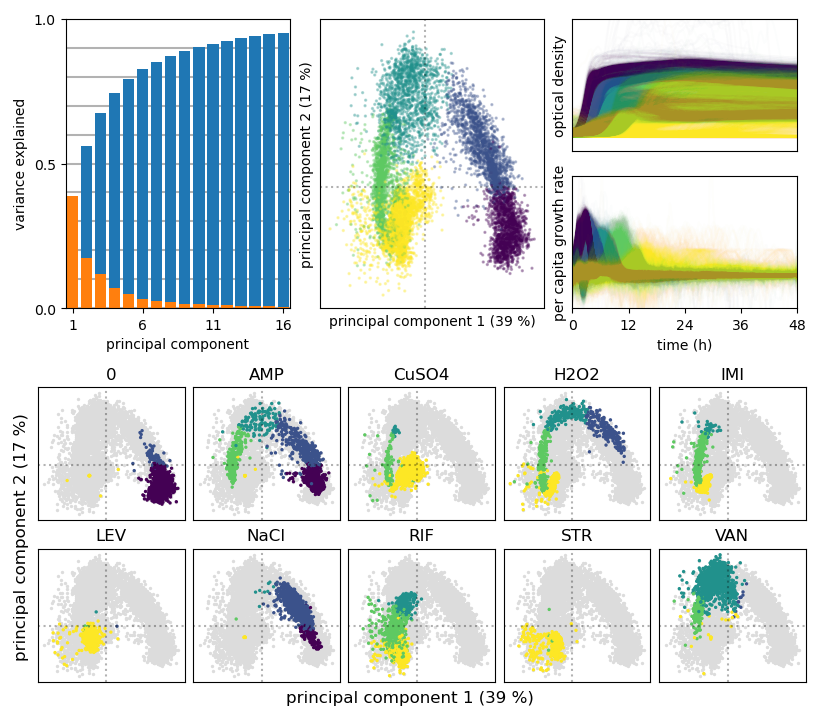

In [44]:
cmap = mpl.colormaps["viridis"]

fig = plt.figure(figsize=(8, 7), constrained_layout=True)
#fig.suptitle("PCA on {}".format(long))
(subfig_t, subfig_b) = fig.subfigures(2, 1) # create top/bottom subfigs

gs1 = subfig_t.add_gridspec(2, 3)

# bar plot
ax = fig.add_subplot(gs1[:,0])
draw_pca_bars(ax, pca, zorder=1,)
ax.set(xticks = [1, 6, 11, 16], yticks = [0, 0.5, 1], )
# PCA biplot
ax = fig.add_subplot(gs1[:,1])
ax.axhline(0, c="k", alpha=0.3, ls="dotted")
ax.axvline(0, c="k", alpha=0.3, ls="dotted")
ax.scatter(X_hat[:,0], X_hat[:,1], c = cmap(cluster_ids / (n_clusters - 1)), s = 2, alpha = 0.3)
ax.set(xticks = [], yticks = [],
       xlabel = "principal component 1 ({} %)".format(round(pca.explained_variance_ratio_[0] * 100)),
       ylabel = "principal component 2 ({} %)".format(round(pca.explained_variance_ratio_[1] * 100)),
      )
# growth curves
for c in range(2):
    ax = fig.add_subplot(gs1[(c, 2)])
    for i in range(n_clusters):
        data = [N, R][c].loc[:,cluster_ids == i]
        plt.plot( np.tile(data.index.values[:,np.newaxis], (1,data.shape[1]), ) / 60, data.values, alpha = 0.01, c = cmap(i / (n_clusters - 1)),)
    ax.set(xlim = (0, data.index.values[-1] / 60), ylim = [(0, 1), (-0.005, 0.015)][c],
           xticks = [[], [0, 12, 24, 36, 48,]][c], yticks = [],
           xlabel = ["", "time (h)"][c], ylabel = ["optical density", "per capita growth rate"][c],
           )


gs2 = subfig_b.add_gridspec(2, 5)
subfig_b.supxlabel("principal component 1 ({} %)".format(round(pca.explained_variance_ratio_[0] * 100)))
subfig_b.supylabel("principal component 2 ({} %)".format(round(pca.explained_variance_ratio_[1] * 100)))

# stressor-clusters
for s, strs in enumerate(strss):
    ax = fig.add_subplot(gs2[s//5, s%5])
    
    ax.axhline(0, c="k", alpha=0.3, ls="dotted")
    ax.axvline(0, c="k", alpha=0.3, ls="dotted")
    
    ax.scatter(X_hat[:,0], X_hat[:,1], c = "gainsboro", s = 2, )
    mask = (R.columns.get_level_values("strs") == strs)
    ax.scatter(X_hat[:,0], X_hat[:,1], c = cmap(cluster_ids / (n_clusters - 1)), s = 2, alpha = np.array(mask, dtype=int), )
    
    ax.set(xticks = [], yticks = [], title = strs)

### SAVING
name = "{}/plot/pcas_{}.png".format(cwd, short)
plt.savefig(name, facecolor='w', edgecolor='w', transparent=False, bbox_inches="tight")
plt.show()

## Plots over time / ATB level

In [45]:
AMPS = pd.read_csv("{}/data/[AMP]s.csv".format(cwd))

In [46]:
bump_value = 0.1
colr_mask = X.index.to_frame()[["ablv", "days"]].apply(lambda x: AMPS.set_index(["ablv", "days"]).loc[tuple([int(xi) for xi in x]), "[AMP]max"], axis=1 )
colr_mask = np.log(1 + colr_mask)
colr_mask = ( colr_mask - colr_mask.min() + bump_value ) / (colr_mask.max() - colr_mask.min() + bump_value)

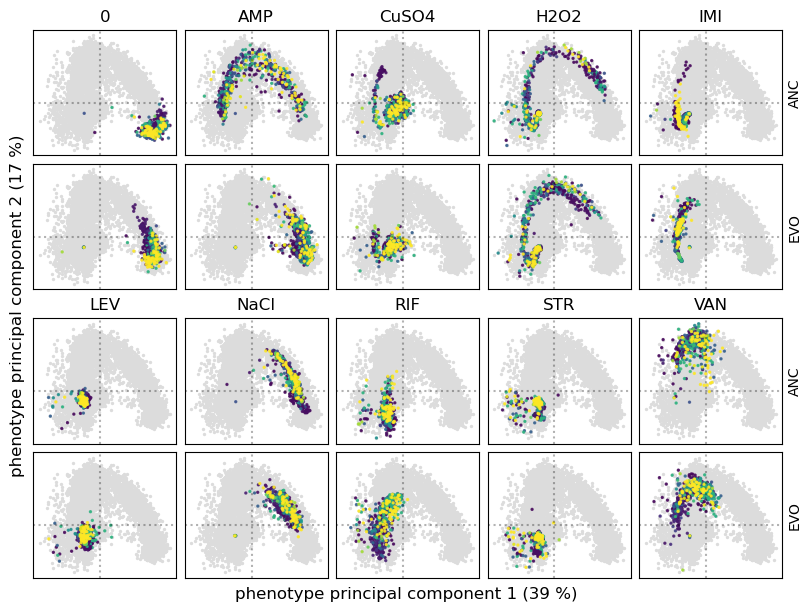

In [48]:
cmap = mpl.colormaps["viridis"]

fig = plt.figure(figsize=(8, 6), constrained_layout=True)
fig.supxlabel("phenotype principal component 1 ({} %)".format(round(pca.explained_variance_ratio_[0] * 100)))
fig.supylabel("phenotype principal component 2 ({} %)".format(round(pca.explained_variance_ratio_[1] * 100)))

gs = fig.add_gridspec(4, 5)

# PCA plot
for s, strs in enumerate(strss):
    for h, hist in enumerate(["ANC", "EVO"]):
        
        ax = fig.add_subplot(gs[2*(s//5)+h, s%5])
        
        ax.axhline(0, c="k", alpha=0.3, ls="dotted")
        ax.axvline(0, c="k", alpha=0.3, ls="dotted")
        
        ax.scatter(X_hat[:,0], X_hat[:,1], c="gainsboro", s=2, )
        mask = (R.columns.get_level_values("strs") == strs) * (R.columns.get_level_values("hist") == hist)
        ax.scatter(X_hat[:,0], X_hat[:,1], c=cmap(colr_mask), s=2, alpha=np.array(mask, dtype=int) * 0.8, )
        
        ax.set(xticks = [], yticks = [], title = strs if h == 0 else None, ylabel = hist if s % 5 == 5 - 1 else None)
        ax.yaxis.set_label_position("right")

### SAVING
name = "{}/plot/pcas_{}_expo.pdf".format(cwd, short)
plt.savefig(name, facecolor='w', edgecolor='w', transparent=False, bbox_inches="tight")
plt.show()

# Comparison of reduced spaces

In [49]:
freq_clids = pd.read_csv("{}/data/Comm_umap.csv".format(cwd), header=[0], index_col=[0,1,2,3]).iloc[:,[0, 1, 2]]
freq_clids = turn_labels_to_str(freq_clids)
freq_clids.columns = ["freq_UMAP1", "freq_UMAP2", "freq_clid"]
freq_dayss = freq_clids.index.get_level_values(level = "days").unique()

In [50]:
X_hat_df = pd.DataFrame(X_hat, index = X.index)[[0, 1]]
X_hat_df = pd.concat([X_hat_df, pd.Series(cluster_ids, index=X.index),], axis = 1,)
X_hat_df.columns = ["phnt_PC1", "phnt_PC2", "phnt_clid"]
phnt_dayss = X_hat_df.index.get_level_values(level = "days").unique()

In [51]:
joint_dayss = joint.index.get_level_values("days").unique()

for d, days in enumerate(joint_dayss):
    
    phnt_days = phnt_dayss[np.argmin(np.abs(np.array([int(x) for x in phnt_dayss]) - days))]
    phnt_clid = X_hat_df.xs(phnt_days, level = "days", axis =0).copy()
    phnt_clid = pd.concat({days: phnt_clid}, names=["days"]).unstack(1)
    phnt_clid.columns.names = ["feat", "strs",]
    
    freq_days = freq_dayss[np.argmin(np.abs(np.array([int(x) for x in freq_dayss]) - days))]
    freq_clid = freq_clids.xs(freq_days, level = "days", axis =0).copy()
    freq_clid = pd.concat({days: freq_clid}, names=["days"])
    freq_clid = pd.concat({"NaN": freq_clid}, names=["strs", "feat",], axis = 1).swaplevel(axis = 1)
    
    joint_clids = pd.concat([phnt_clid, freq_clid,], axis=1, ) if d == 0 else pd.concat([joint_clids, pd.concat([phnt_clid, freq_clid,], axis = 1, ),], axis=0)

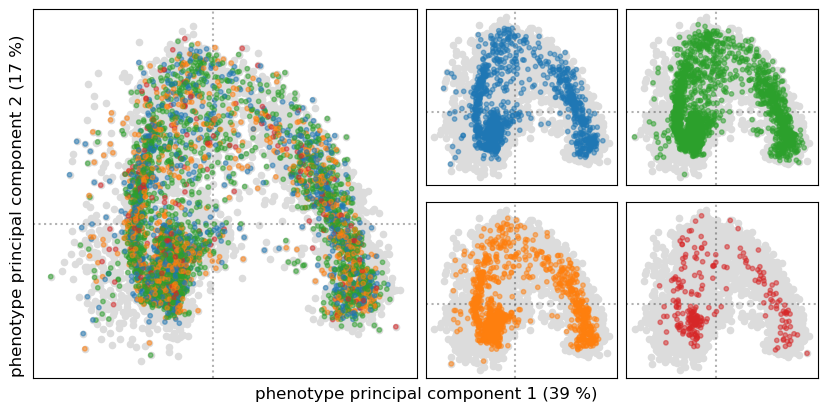

In [53]:
cmap = mpl.colormaps["tab10"]

fig = plt.figure(figsize=(12, 4), constrained_layout=True)
fig.supxlabel("phenotype principal component 1 ({} %)".format(round(pca.explained_variance_ratio_[0] * 100)), x=0.35)
fig.supylabel("phenotype principal component 2 ({} %)".format(round(pca.explained_variance_ratio_[1] * 100)))

gs = fig.add_gridspec(2, 6)

ax = fig.add_subplot(gs[:,:2])

ax.axhline(0, c="k", alpha=0.3, ls="dotted")
ax.axvline(0, c="k", alpha=0.3, ls="dotted")
ax.scatter(X_hat[:,0], X_hat[:,1], c="gainsboro", s=20, zorder=1, )
ax.scatter(joint_clids.xs("phnt_PC1", axis=1, level="feat"), joint_clids.xs("phnt_PC2", axis=1, level="feat"), c=cmap(np.tile(joint_clids.loc[:,("freq_clid", "NaN")], 10)), s=10, alpha=0.5, zorder=2, )

ax.set(xticks = [], yticks = [], )

# PCA plot
for cl, clid in enumerate(joint_clids.loc[:,("freq_clid", "NaN")].unique()):
    ax = fig.add_subplot(gs[cl // 2, cl % 2 + 2])
    ax.axhline(0, c="k", alpha=0.3, ls="dotted")
    ax.axvline(0, c="k", alpha=0.3, ls="dotted")
    
    ax.scatter(X_hat[:,0], X_hat[:,1], c="gainsboro", s=20, zorder=1, )
    ax.scatter(joint_clids.xs("phnt_PC1", axis=1, level="feat"), joint_clids.xs("phnt_PC2", axis=1, level="feat"), c=cmap(np.tile(joint_clids.loc[:,("freq_clid", "NaN")], 10)), s=10,
               alpha= 0.5 * (np.tile(joint_clids.loc[:,("freq_clid", "NaN")], 10) == clid), zorder=2, )
    
    ax.set(xticks = [], yticks = [], )

### SAVING
name = "{}/plot/PCA_R_freq_clid.pdf".format(cwd, short)
plt.savefig(name, facecolor='w', edgecolor='w', transparent=False, bbox_inches="tight")
plt.show()